# 03 - EDA + RandomForest baseline (Option A, 11 flows demo)
Input: `data/processed/labeled_flows.csv` (6 suspicious / 5 normal).
Rule: label=1 neu rst>0 va (duration<6 hoac n_pkts<16).

In [1]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv(r"D:\PATTT\data\processed\labeled_flows.csv")
hosts = pd.read_csv(r"D:\PATTT\data\processed\hosts.csv")
print(df['label'].value_counts())
display(df[['src','dst','n_pkts','duration','rst','label']])
display(hosts)

label
1    6
0    5
Name: count, dtype: int64


,src,dst,n_pkts,duration,rst,label
0,192.168.1.254,122.225.98.197,11,1.935702,2,1
1,192.168.1.254,103.235.46.234,191,20.341228,0,0
2,192.168.1.254,42.96.141.35,13,3.909843,1,1
3,192.168.1.254,42.96.141.35,15,5.249714,3,1
4,192.168.1.254,42.96.141.35,8,5.091215,1,1
5,192.168.1.254,42.120.158.95,11,0.899358,0,0
6,192.168.1.254,42.120.158.95,15,1.329531,0,0
7,192.168.1.254,42.120.158.95,9,1.222337,0,0
8,192.168.1.254,42.96.141.35,7,0.549368,1,1
9,192.168.1.254,42.96.141.35,6,3.286658,1,1


,src,window,n_flows,n_dst_ip,n_dst_port,conn_per_sec,avg_duration,total_bytes,syn_no_ack_ratio,rst_ratio,port_entropy,start_std,file
0,192.168.1.254,24280323,2,2,2,0.889496,11.138465,173358,0.0,0.500000,1.0,1.589905,attack-injection-hao123.pcap
1,192.168.1.254,24280320,9,2,1,1.459410,2.794639,71668,0.0,0.555556,-0.0,2.706466,attack-injection-id1cn.pcap


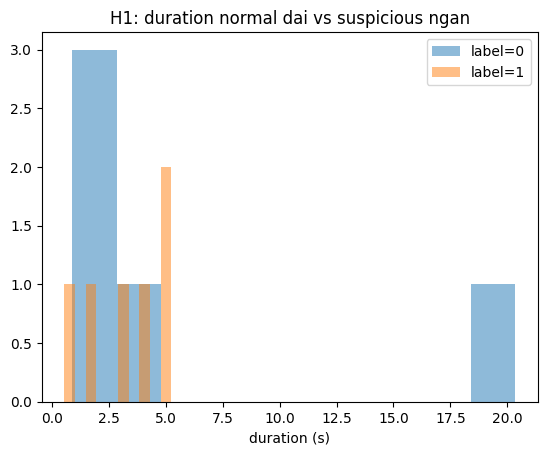

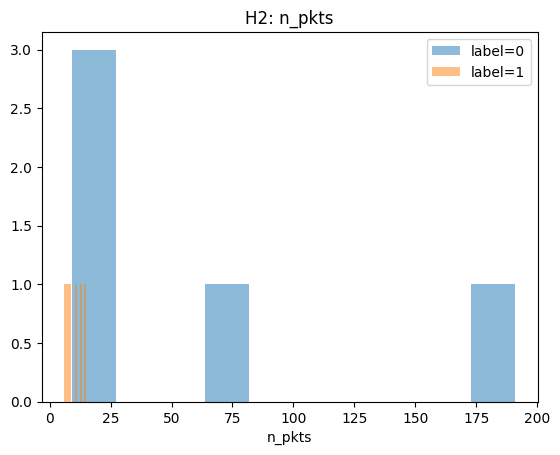

In [2]:
# 1. Hist duration theo label
for lb in [0,1]:
    plt.hist(df[df.label==lb]['duration'], alpha=0.5, label=f'label={lb}')
plt.xlabel('duration (s)'); plt.legend(); plt.title('H1: duration normal dai vs suspicious ngan'); plt.show()
# 2. Hist n_pkts theo label
for lb in [0,1]:
    plt.hist(df[df.label==lb]['n_pkts'], alpha=0.5, label=f'label={lb}')
plt.xlabel('n_pkts'); plt.legend(); plt.title('H2: n_pkts'); plt.show()

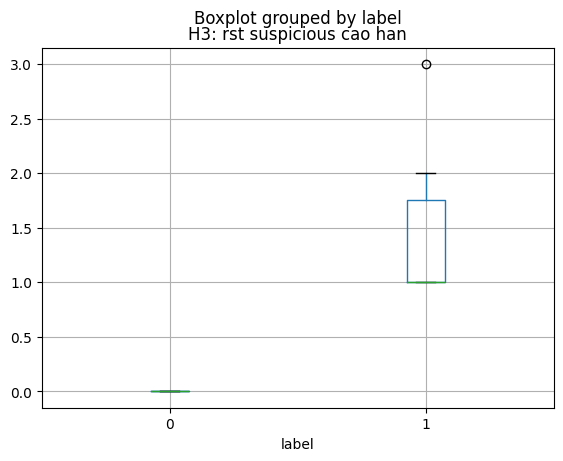

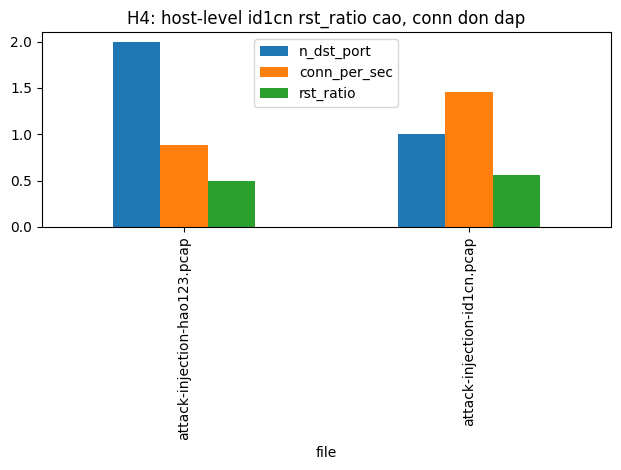

In [3]:
# 3. Boxplot rst theo label
df.boxplot(column='rst', by='label'); plt.title('H3: rst suspicious cao han'); plt.show()
# 4. Bar host-level
hosts.plot(x='file', y=['n_dst_port','conn_per_sec','rst_ratio'], kind='bar')
plt.title('H4: host-level id1cn rst_ratio cao, conn don dap'); plt.tight_layout(); plt.show()

## RF baseline (chay `python src/train_classifier.py`)
Ket qua tren test 4 mau: Acc=1.0, Pre=1.0, Rec=1.0, F1=1.0, CM [[2,0],[0,2]].
Top feature: mean_iat (0.24), rst (0.24), duration (0.13).
Luu y: tap 11 mau chi demo pipeline, chua y nghia thong ke. Can CIC-IDS2017/CTU-13 o Giai doan 3.